# Đề tài 13 — Phân loại chữ số viết tay (Digits)

Notebook thực nghiệm chính gồm 16 mục. Kết quả đang trình bày thuộc run **20261117T081201Z_fd32180f**;
test chỉ được dùng sau khi khóa lựa chọn bằng CV. Các nhận định là **dự thảo dựa trên output thật,
chưa được nhóm xác nhận**. Không xem dự thảo là đóng góp hoặc kết luận đã thông qua của sinh viên.

Chạy từ gốc project. `RUN_EXPERIMENTS=True` tạo một run mới; không cần chạy lại để mở demo.
App tải Pipeline cố định trong `models/registry.json`. Không thay artifact chính thức hoặc tuning sau khi xem test.
Toàn bộ bảng và hình nguồn được lập chỉ mục trong [docs/RESULTS_INDEX.md](docs/RESULTS_INDEX.md).


## 1. Bài toán, mục tiêu và tiêu chí thành công

Học có giám sát, phân lớp đa lớp: một ảnh → nhãn nguyên 0–9. Digits là ảnh 8×8, khác MNIST 28×28.
Mục tiêu: so sánh Logistic Regression trên pixel thô với KNN và MLP, kiểm chứng tác động chuẩn hóa,
phân tích nhầm lẫn và chi phí tính toán. Phạm vi là ảnh giống Digits; chưa xác nhận sử dụng cho ảnh điện thoại.

Quy tắc đặt trước: chọn **macro F1 trung bình CV cao nhất**; hòa tuyệt đối chọn tên theo thứ tự chữ cái.
Macro F1 tính F1 riêng từng lớp rồi lấy trung bình, giúp 10 chữ số có vai trò ngang nhau và xét cả precision/recall.
Accuracy bổ sung cách đọc trực tiếp: tỷ lệ ảnh dự đoán đúng. Dữ liệu khá cân bằng nên hai độ đo có thể gần nhau,
nhưng không hoán đổi tên hoặc giá trị. Precision/recall macro giúp hiểu thêm loại sai.
Thành công là quy trình tái lập, không rò rỉ, đủ so sánh baseline và trả lời 5 câu hỏi bằng kết quả thật;
không đặt điều kiện MLP nhất định thắng. Thông tin thành viên và phân công: **chưa được cung cấp**.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
from time import perf_counter
from io import BytesIO
import hashlib
import json
import platform
import sys
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV, cross_validate, learning_curve,
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)
from threadpoolctl import threadpool_limits

SEED = 42
LABELS = np.arange(10)
RUN_EXPERIMENTS = True
# Điền sau khi xem kiểm tra dữ liệu; không dùng cờ này thay cho nhật ký quyết định.
CLEANING_DECISION = "Giữ nguyên dữ liệu: không thiếu, sai miền hoặc trùng; cờ IQR độ sáng không đủ bằng chứng loại ảnh."
STUDENT_PROTOCOL_NOTE = "Huấn luyện lần đầu đã được cho phép; giữ seed/split/grid/tiêu chí CV trước khi xem test."
SELECTION_RULE = "highest_cv_f1_macro_mean_then_name_ascending"
ROOT = Path.cwd()
assert (ROOT / "docs/Huong_Dan_Do_An_CuoiKy.pdf").is_file(), "Mở notebook từ gốc project."
# Mỗi lần chạy tạo thư mục riêng, giữ nguyên kết quả cũ.
RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
OUT = ROOT / "outputs" / RUN_ID
MODEL_OUT = ROOT / "models" / RUN_ID
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=False)
PACKAGES = ["numpy", "pandas", "matplotlib", "seaborn", "scikit-learn", "joblib",
            "notebook", "ipykernel", "nbformat", "nbclient", "scipy", "threadpoolctl"]
environment = {"python": sys.version, "platform": platform.platform(),
               "packages": {name: version(name) for name in PACKAGES},
               "seed": SEED, "run_id": RUN_ID, "selection_rule": SELECTION_RULE,
               "student_experiments_requested": RUN_EXPERIMENTS}
(OUT / "environment.json").write_text(json.dumps(environment, indent=2, ensure_ascii=False), encoding="utf-8")
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})
pd.set_option("display.max_rows", 70)
print("Run:", RUN_ID, "| Chế độ notebook:", "thực nghiệm" if RUN_EXPERIMENTS else "khung hỗ trợ")


def save_figure(fig, filename):
    fig.savefig(FIGURES / filename, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


Run: 20261117T081201Z_fd32180f | Chế độ notebook: thực nghiệm


## 2. Đọc dữ liệu và ghi nguồn

Nguồn chính thức: [scikit-learn load_digits](https://scikit-learn.org/1.7/modules/generated/sklearn.datasets.load_digits.html),
[UCI Optical Recognition of Handwritten Digits](https://archive.ics.uci.edu/dataset/80/optical+recognition+of+handwritten+digits).
`load_digits()` đóng gói dữ liệu trong scikit-learn, không cần tải MNIST. Ghi lại DESCR đi kèm bản cài
để tra nguồn gốc. Dữ liệu chứa ảnh số, không sử dụng thông tin cá nhân của nhóm.


In [2]:
digits = load_digits()
X = pd.DataFrame(digits.data, columns=digits.feature_names)
y = pd.Series(digits.target, name="target")
raw_data = X.assign(target=y)
schema = pd.DataFrame({"dtype": raw_data.dtypes.astype(str),
                       "missing_count": raw_data.isna().sum(),
                       "missing_ratio": raw_data.isna().mean()})
data_summary = {"X_shape": list(X.shape), "images_shape": list(digits.images.shape),
                "y_shape": list(y.shape), "n_samples": len(X), "n_features": X.shape[1],
                "labels": sorted(y.unique().tolist()), "pixel_min": float(X.min().min()),
                "pixel_max": float(X.max().max()), "X_dtype": str(digits.data.dtype),
                "y_dtype": str(y.dtype)}
display(pd.Series(data_summary, name="giá trị"))
display(schema)
schema.to_csv(OUT / "column_schema.csv", encoding="utf-8-sig", index_label="column")
(OUT / "data_summary.json").write_text(json.dumps(data_summary, indent=2), encoding="utf-8")
(OUT / "dataset_description.txt").write_text(digits.DESCR, encoding="utf-8")
DATA_SHA256 = hashlib.sha256(np.ascontiguousarray(X).tobytes() + np.ascontiguousarray(y).tobytes()).hexdigest()
print("SHA256 dữ liệu (X rồi y):", DATA_SHA256)


X_shape                             [1797, 64]
images_shape                      [1797, 8, 8]
y_shape                                 [1797]
n_samples                                 1797
n_features                                  64
labels          [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
pixel_min                                  0.0
pixel_max                                 16.0
X_dtype                                float64
y_dtype                                  int64
Name: giá trị, dtype: object

,dtype,missing_count,missing_ratio
pixel_0_0,float64,0,0.0
pixel_0_1,float64,0,0.0
pixel_0_2,float64,0,0.0
pixel_0_3,float64,0,0.0
pixel_0_4,float64,0,0.0
pixel_0_5,float64,0,0.0
pixel_0_6,float64,0,0.0
pixel_0_7,float64,0,0.0
pixel_1_0,float64,0,0.0
pixel_1_1,float64,0,0.0


SHA256 dữ liệu (X rồi y): f6d9e39f37dc45d327f6db33428ee58970ccceabb2535a5c179de35886b70443


## 3. Kiểm tra chất lượng và quyết định xử lý

Kiểu lưu float64 của pixel hợp lệ vì giá trị thực tế là số nguyên hữu hạn trong 0–16. Nhãn int64 nằm trong 0–9.
Kiểm tra riêng giá trị thiếu từng cột, sai kiểu/miền, ảnh trùng, nhãn mâu thuẫn và ảnh hằng.
Không loại ảnh chỉ vì nét dày, khác cách viết hoặc dự đoán khó. Kiểm tra dưới đây không sửa dữ liệu.
Nếu nguồn dữ liệu khác xuất hiện lỗi, phải xác minh trước; imputer/scaler nếu cần phải học bên trong CV Pipeline.


In [3]:
numeric_X = X.apply(pd.to_numeric, errors="coerce")
numeric_y = pd.to_numeric(y, errors="coerce")
values = numeric_X.to_numpy()
finite_pixels = np.isfinite(values)
bad_pixel = (~finite_pixels) | (values < 0) | (values > 16) | (values != np.floor(values))
bad_labels = (~np.isfinite(numeric_y)) | (~numeric_y.isin(LABELS)) | (numeric_y != np.floor(numeric_y))
# Tuple giữ so sánh chính xác toàn bộ 64 pixel, không làm tròn hay chỉ so nhãn.
image_keys = pd.Series([tuple(row) for row in values], index=X.index, name="image_key")
duplicate_mask = image_keys.duplicated(keep=False)
label_conflicts = pd.DataFrame({"key": image_keys, "label": y}).groupby("key")["label"].nunique().gt(1)
constant_images = numeric_X.nunique(axis=1).le(1)
quality = {"missing_cells": int(raw_data.isna().sum().sum()),
           "nonnumeric_pixels": int((numeric_X.isna() & X.notna()).sum().sum()),
           "invalid_pixel_cells": int(bad_pixel.sum()), "invalid_labels": int(bad_labels.sum()),
           "duplicate_image_rows": int(duplicate_mask.sum()),
           "duplicate_extra_rows": int(image_keys.duplicated().sum()),
           "conflicting_image_groups": int(label_conflicts.sum()),
           "constant_images": int(constant_images.sum())}
display(pd.Series(quality, name="số lượng"))
(OUT / "data_quality.json").write_text(json.dumps(quality, indent=2), encoding="utf-8")
pd.DataFrame({"sample_index": X.index, "duplicate": duplicate_mask,
              "constant_image": constant_images}).to_csv(OUT / "quality_flags.csv", index=False)
assert not bad_pixel.any(), "Có pixel không hợp lệ; nhóm cần điều tra trước khi tiếp tục."
assert not bad_labels.any(), "Có nhãn không hợp lệ; nhóm cần điều tra."
assert not label_conflicts.any(), "Có ảnh cùng pixel khác nhãn; nhóm cần điều tra."
assert X.shape[1] == 64 and np.array_equal(values.reshape(-1, 8, 8), digits.images)


missing_cells               0
nonnumeric_pixels           0
invalid_pixel_cells         0
invalid_labels              0
duplicate_image_rows        0
duplicate_extra_rows        0
conflicting_image_groups    0
constant_images             0
Name: số lượng, dtype: int64

**Nhật ký xử lý — dự thảo cần nhóm kiểm tra và xác nhận**

| Kiểm tra | Bằng chứng run chính thức | Quyết định thực nghiệm và lý do |
|---|---|---|
| Thiếu / sai kiểu | 65 cột gồm 64 pixel và nhãn đều thiếu 0%; pixel hữu hạn, nguyên dù lưu float64 | Giữ nguyên; không có cơ sở thêm imputer hoặc ép kiểu sửa dữ liệu |
| Trùng / nhãn mâu thuẫn | Không có ảnh trùng chính xác hoặc cùng ảnh khác nhãn | Giữ nguyên 1.797 mẫu; không cần loại trùng |
| Pixel ngoài miền / nhãn sai / ảnh hằng | Các số đếm đều 0 | Giữ nguyên; không có lỗi hợp đồng dữ liệu |
| Cờ IQR độ sáng, chỉ trên train | id 1747, 818, 1766; mean pixel 6,671875; 6,765625; 6,546875 | Giữ cả ba; đều là ảnh nhãn 1 có nét sáng dày, không hằng, không ngoài miền. Cờ thống kê không chứng minh ảnh lỗi |

Ba ảnh IQR được xem trực tiếp trong lượt kiểm tra cuối; chúng có 36, 39, 39 pixel khác 0.
Người xác nhận của nhóm: **chưa có thông tin**. Chính sách giữ nguyên là chính sách đã dùng trong run,
không phải một quyết định mới dựa vào điểm test. Nguồn: `data_quality.json`, `column_schema.csv`,
`train_image_diagnostics.csv` trong thư mục run chính thức. Các kiểm tra trùng xuyên tập ở mục 4.


## 4. Chia train/test và kiểm tra trùng xuyên tập

80/20, stratify=y, seed 42. Chỉ báo cáo kích thước và kiểm tra hợp lệ/trùng; không EDA test.
Kiểm tra cả CV để ảnh giống hệt không xuất hiện ở train và validation của fold.
Nếu phát hiện trùng, dừng và ghi quyết định; không âm thầm đổi chiến lược chia đã yêu cầu.


In [4]:
train_idx, test_idx = train_test_split(X.index.to_numpy(), test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X.loc[train_idx].copy(), X.loc[test_idx].copy()
y_train, y_test = y.loc[train_idx].copy(), y.loc[test_idx].copy()
overlap = set(image_keys.loc[train_idx]) & set(image_keys.loc[test_idx])
assert not (set(train_idx) & set(test_idx))
assert len(train_idx) + len(test_idx) == len(X)
assert not overlap, "Ảnh trùng xuyên train/test; cần nhóm quyết định xử lý trước khi huấn luyện."
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_splits = list(cv.split(X_train, y_train))
fold_rows = []
for fold, (fit_idx, val_idx) in enumerate(cv_splits, start=1):
    fit_keys = set(image_keys.loc[X_train.index[fit_idx]])
    val_keys = set(image_keys.loc[X_train.index[val_idx]])
    n_overlap = len(fit_keys & val_keys)
    assert n_overlap == 0, "Ảnh trùng xuyên CV; nhóm cần quyết định trước khi huấn luyện."
    assert len(np.unique(y_train.iloc[fit_idx])) == len(np.unique(y_train.iloc[val_idx])) == 10
    fold_rows.append({"fold": fold, "fit_n": len(fit_idx), "validation_n": len(val_idx), "overlap_images": n_overlap})
split_info = {"train_n": len(train_idx), "test_n": len(test_idx), "test_size": 0.2,
              "stratify": "y", "random_state": SEED, "overlap_images": len(overlap), "data_sha256": DATA_SHA256}
display(pd.Series(split_info))
display(pd.DataFrame(fold_rows))
pd.DataFrame({"sample_index": X.index, "split": np.where(X.index.isin(train_idx), "train", "test")}).to_csv(OUT / "split_indices.csv", index=False)
pd.DataFrame(fold_rows).to_csv(OUT / "cv_fold_audit.csv", index=False)
(OUT / "split_summary.json").write_text(json.dumps(split_info, indent=2), encoding="utf-8")


train_n                                                        1437
test_n                                                          360
test_size                                                       0.2
stratify                                                          y
random_state                                                     42
overlap_images                                                    0
data_sha256       f6d9e39f37dc45d327f6db33428ee58970ccceabb2535a...
dtype: object

,fold,fit_n,validation_n,overlap_images
0,1,1149,288,0
1,2,1149,288,0
2,3,1150,287,0
3,4,1150,287,0
4,5,1150,287,0


207

## 5. Sáu biểu đồ EDA chỉ trên train

Các hình dưới chỉ dùng 1.437 mẫu train; mỗi nhận định dự thảo gắn với hình và số liệu cùng run chính thức.
PCA chỉ để quan sát 2D, không đưa vào mô hình. IQR độ sáng chỉ gắn cờ, không tự loại ảnh;
`review_train_image(id)` cho phép xem lại các id train và quyết định giữ đã ghi ở mục 3.


In [5]:
image_diagnostics = pd.DataFrame({
    "mean_intensity": X_train.mean(axis=1),
    "nonzero_pixels": X_train.ne(0).sum(axis=1),
    "constant_image": X_train.nunique(axis=1).le(1),
})
q1, q3 = image_diagnostics["mean_intensity"].quantile([0.25, 0.75])
iqr = q3 - q1
image_diagnostics["brightness_iqr_flag"] = ~image_diagnostics["mean_intensity"].between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)
image_diagnostics.to_csv(OUT / "train_image_diagnostics.csv", index_label="sample_index")
print("Số ảnh train được gắn cờ IQR độ sáng (chưa kết luận lỗi):", int(image_diagnostics["brightness_iqr_flag"].sum()))
display(pd.concat([image_diagnostics.nsmallest(3, "mean_intensity"), image_diagnostics.nlargest(3, "mean_intensity")]))


def review_train_image(sample_index):
    """Nhóm tự gọi để xem bằng chứng; chỉ chấp nhận id trong train."""
    if sample_index not in X_train.index:
        raise ValueError("Chỉ xem ảnh train trước khi khóa mô hình")
    fig, ax = plt.subplots(figsize=(4, 4), layout="constrained")
    im = ax.imshow(X_train.loc[sample_index].to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.grid(False)
    ax.set(title=f"Kiểm tra ảnh train id={sample_index}, nhãn={y_train.loc[sample_index]}",
           xlabel="Cột pixel", ylabel="Hàng pixel")
    fig.colorbar(im, ax=ax, label="Cường độ pixel (0–16)")
    plt.show()
    plt.close(fig)

Số ảnh train được gắn cờ IQR độ sáng (chưa kết luận lỗi): 3


,mean_intensity,nonzero_pixels,constant_image,brightness_iqr_flag
1389,3.531250,25,False,False
1631,3.562500,22,False,False
1331,3.593750,28,False,False
818,6.765625,39,False,True
1747,6.671875,36,False,True
1766,6.546875,39,False,True


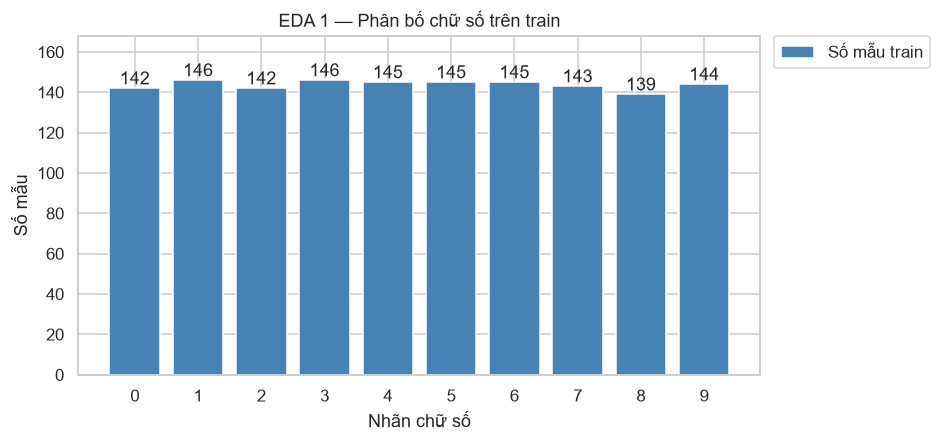

In [6]:
class_counts = y_train.value_counts().sort_index().reindex(LABELS, fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_counts.index, class_counts.values, label="Số mẫu train", color="steelblue")
ax.set(title="EDA 1 — Phân bố chữ số trên train", xlabel="Nhãn chữ số", ylabel="Số mẫu", xticks=LABELS)
ax.bar_label(ax.containers[0])
ax.margins(y=0.15)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), borderaxespad=0)
save_figure(fig, "eda_01_class_distribution.png")
class_counts.to_csv(OUT / "train_class_counts.csv", index_label="label", header=["count"])


**EDA 1 — dự thảo.** Số mẫu lớp 0–9 lần lượt là 142, 146, 142, 146, 145, 145, 145, 143, 139, 144.
Lớp 8 ít nhất (139), lớp 1 và 3 nhiều nhất (146), chênh 7 mẫu; phân bố khá cân bằng.
Không có cơ sở phải tăng mẫu nhân tạo chỉ từ phân bố này. Macro F1 vẫn cho mỗi lớp trọng số ngang nhau.
Nguồn: `train_class_counts.csv`.


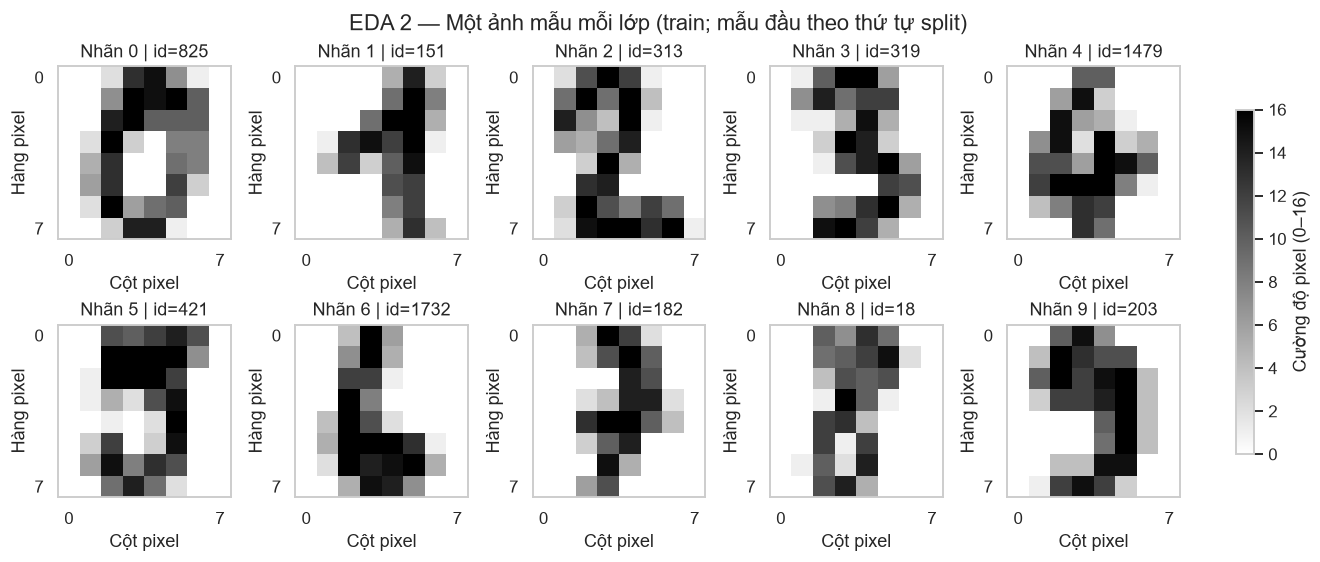

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5), layout="constrained")
for label, ax in zip(LABELS, axes.flat):
    sample_id = y_train[y_train == label].index[0]
    im = ax.imshow(X_train.loc[sample_id].to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.grid(False)
    ax.set(title=f"Nhãn {label} | id={sample_id}", xlabel="Cột pixel", ylabel="Hàng pixel", xticks=[0, 7], yticks=[0, 7])
fig.suptitle("EDA 2 — Một ảnh mẫu mỗi lớp (train; mẫu đầu theo thứ tự split)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Cường độ pixel (0–16)", shrink=0.8)
save_figure(fig, "eda_02_sample_images.png")


**EDA 2 — dự thảo.** Mỗi hàng 64 đặc trưng được reshape theo thứ tự hàng thành ảnh 8×8;
pixel 0 là tối, 16 là sáng. Các ảnh mẫu có nét và độ nghiêng khác nhau; ví dụ số 1 id 151 nghiêng,
số 8 id 18 có hai vùng vòng nét ở độ phân giải thấp. Chỉ 64 pixel nên chi tiết nét mảnh dễ mất;
một ảnh mỗi lớp không đại diện toàn bộ cách viết. Các id hiển thị đều thuộc train.


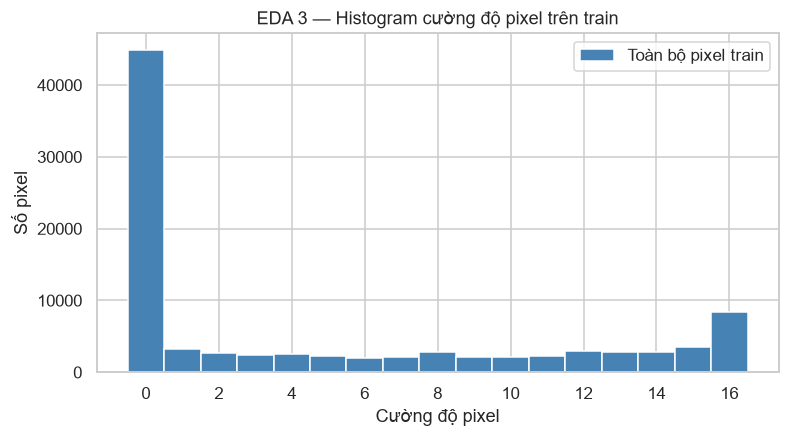

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(X_train.to_numpy().ravel(), bins=np.arange(-0.5, 17.5, 1), color="steelblue", label="Toàn bộ pixel train")
ax.set(title="EDA 3 — Histogram cường độ pixel trên train", xlabel="Cường độ pixel", ylabel="Số pixel", xticks=np.arange(0, 17, 2))
ax.legend()
save_figure(fig, "eda_03_pixel_histogram.png")


**EDA 3 — dự thảo.** Pixel nằm trong 0–16; khoảng **48,86%** pixel train bằng 0,
phù hợp nền tối chiếm nhiều diện tích. Các giá trị sáng vẫn cần để mô tả nét chữ;
pixel 0 hợp lệ, không phải missing. Chuẩn hóa trong Pipeline đổi thang theo từng vị trí,
không phải thay pixel 0 bằng giá trị điền thiếu. Tỷ lệ tính trên 1.437×64 pixel train.


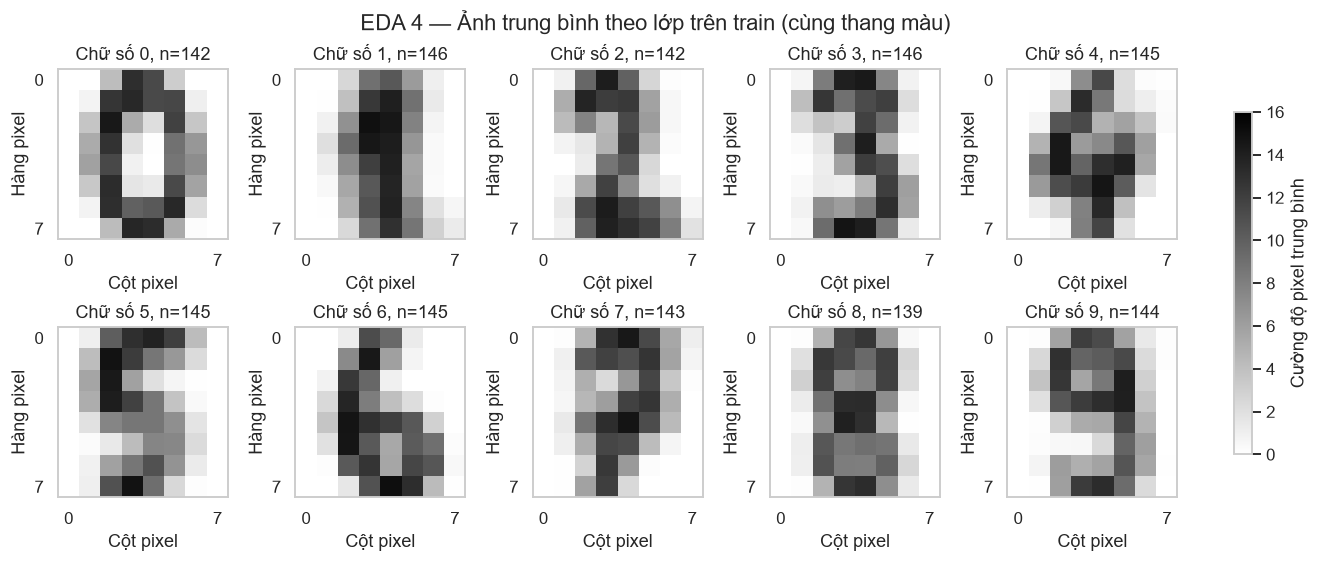

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5), layout="constrained")
for label, ax in zip(LABELS, axes.flat):
    mean_image = X_train.loc[y_train == label].mean().to_numpy().reshape(8, 8)
    im = ax.imshow(mean_image, cmap="gray_r", vmin=0, vmax=16)
    ax.grid(False)
    ax.set(title=f"Chữ số {label}, n={class_counts[label]}", xlabel="Cột pixel", ylabel="Hàng pixel", xticks=[0, 7], yticks=[0, 7])
fig.suptitle("EDA 4 — Ảnh trung bình theo lớp trên train (cùng thang màu)")
fig.colorbar(im, ax=axes.ravel().tolist(), label="Cường độ pixel trung bình", shrink=0.8)
save_figure(fig, "eda_04_class_mean_images.png")


**EDA 4 — dự thảo.** Ảnh trung bình lớp 0 còn vùng rỗng ở giữa, lớp 1 tập trung thành nét dọc,
lớp 8 có vùng nét ở cả nửa trên và dưới. Nét trung bình mờ hơn ảnh riêng vì vị trí/cách viết thay đổi.
Một số vùng nét của 8 và 1 có thể chồng nhau khi ảnh nhỏ; đây chỉ là giả thuyết hình học,
được đối chiếu với lỗi 8→1 sau khóa mô hình, không dùng hình trung bình để dự đoán accuracy.


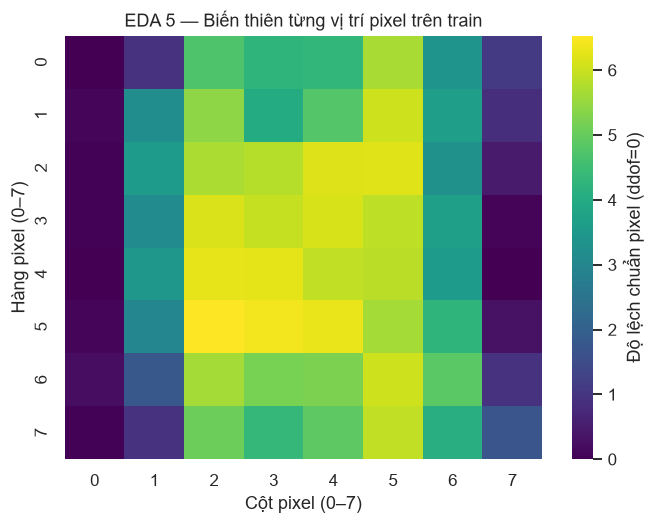

In [10]:
fig, ax = plt.subplots(figsize=(7, 5))
pixel_std = X_train.std(ddof=0).to_numpy().reshape(8, 8)
sns.heatmap(pixel_std, cmap="viridis", ax=ax, cbar_kws={"label": "Độ lệch chuẩn pixel (ddof=0)"})
ax.set(title="EDA 5 — Biến thiên từng vị trí pixel trên train", xlabel="Cột pixel (0–7)", ylabel="Hàng pixel (0–7)")
save_figure(fig, "eda_05_pixel_std_heatmap.png")


**EDA 5 — dự thảo.** Nhiều vị trí bên trong biến thiên mạnh hơn mép nền.
Độ lệch chuẩn lớn nhất khoảng **6,5311** ở hàng 5, cột 2 (đánh số từ 0).
Các cột vector 0, 32, 39 có độ lệch chuẩn 0 trên train. Biến thiên đo sự thay đổi cường độ,
không trực tiếp đo tầm quan trọng dự đoán; giữ đủ 64 cột cho phép so sánh cùng biểu diễn đầu vào.


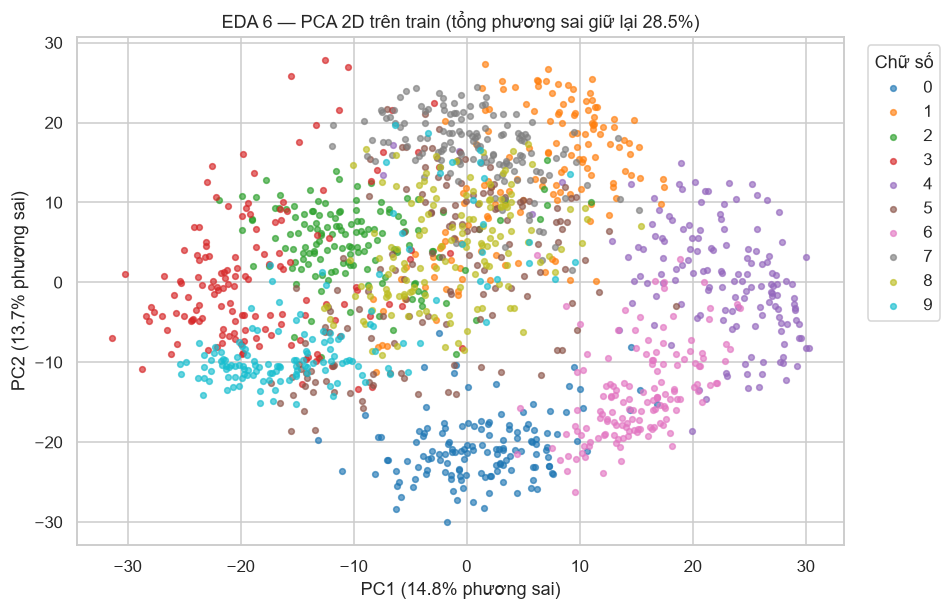

In [11]:
# PCA tự center; giữ pixel thô để quan sát phương sai trên cùng miền 0–16.
pca_eda = PCA(n_components=2, svd_solver="full", random_state=SEED)
train_2d = pca_eda.fit_transform(X_train)
fig, ax = plt.subplots(figsize=(9, 6))
palette = sns.color_palette("tab10", n_colors=10)
for label in LABELS:
    mask = y_train.to_numpy() == label
    ax.scatter(train_2d[mask, 0], train_2d[mask, 1], s=14, alpha=0.65, color=palette[label], label=str(label))
ratios = pca_eda.explained_variance_ratio_
ax.set(title=f"EDA 6 — PCA 2D trên train (tổng phương sai giữ lại {ratios.sum():.1%})",
       xlabel=f"PC1 ({ratios[0]:.1%} phương sai)", ylabel=f"PC2 ({ratios[1]:.1%} phương sai)")
ax.legend(title="Chữ số", bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure(fig, "eda_06_pca_2d.png")
pd.DataFrame(train_2d, index=X_train.index, columns=["PC1", "PC2"]).assign(label=y_train).to_csv(OUT / "train_pca_2d.csv", index_label="sample_index")


**EDA 6 — dự thảo.** PC1 giữ 14,7592%, PC2 giữ 13,7427% phương sai, tổng **28,5019%**.
Một số vùng lớp 0/4 dễ nhìn hơn, nhiều lớp vẫn chồng lấn. Còn hơn 71% phương sai ngoài mặt phẳng này,
nên chồng lấn 2D không chứng minh các mô hình 64 chiều không phân loại được.
PCA chỉ fit train và không nằm trong Pipeline thực nghiệm. Nguồn: `train_pca_2d.csv` và hình PCA.


## 6. Baseline chính: Logistic Regression trên pixel thô

Pipeline gồm `scale='passthrough'` và LogisticRegression(C=1, solver='lbfgs', max_iter=3000, seed=42).
Giữ pixel thô để làm đối chứng cố định cho câu hỏi đề tài, không phải kết luận Logistic Regression
không cần chuẩn hóa. Không tuning baseline và không sử dụng PCA EDA làm đặc trưng mô hình.


In [12]:
def make_baseline():
    return Pipeline([
        ("scale", "passthrough"),
        ("clf", LogisticRegression(max_iter=3000, solver="lbfgs", random_state=SEED)),
    ])


## 7. Hai mô hình so sánh: KNN và MLP bằng Pipeline

Pipeline có hai bước `scale` và `clf`. KNN bắt đầu với k=5 và StandardScaler;
MLP bắt đầu với StandardScaler và MLP_INITIAL ở mục 10. Scaler chỉ fit trên phần train
của từng fold. KNN nhạy với khoảng cách, MLP nhạy với thang đầu vào trong tối ưu.
API: [Pipeline](https://scikit-learn.org/1.7/modules/generated/sklearn.pipeline.Pipeline.html).


In [13]:
def make_comparison_models():
    return {
        "knn": Pipeline([("scale", StandardScaler()),
                         ("clf", KNeighborsClassifier(n_neighbors=5, n_jobs=1))]),
        "mlp": Pipeline([("scale", StandardScaler()), ("clf", MLPClassifier(**MLP_INITIAL))]),
    }


## 8. Thí nghiệm MLP có/không chuẩn hóa

Cố định MLP_INITIAL, cùng 5 folds/seed/số luồng, chỉ thay passthrough và StandardScaler.
Lưu đủ 10 hàng, mỗi điều kiện × 5 folds, với 4 độ đo và thời gian fit. Không sử dụng test.
Chọn scaler theo mean CV macro F1 cao hơn; hòa chọn StandardScaler. Sau đó chỉ tuning kiến trúc/alpha.
Việc dùng lại CV cho lựa chọn làm CV có thiên lệch lựa chọn; test cuối vẫn được giữ độc lập.


In [14]:
def run_scaling_experiment(X_train, y_train, cv_splits):
    scoring = {"accuracy": "accuracy", "precision_macro": "precision_macro",
               "recall_macro": "recall_macro", "f1_macro": "f1_macro"}
    rows = []
    for condition, scaler in [("raw", "passthrough"), ("standard", StandardScaler())]:
        pipeline = Pipeline([("scale", scaler), ("clf", MLPClassifier(**MLP_INITIAL))])
        scores = cross_validate(pipeline, X_train, y_train, cv=cv_splits,
                                scoring=scoring, n_jobs=1, error_score="raise")
        for fold in range(len(cv_splits)):
            rows.append({"scaling": condition, "fold": fold + 1,
                         **{metric: float(scores[f"test_{metric}"][fold]) for metric in scoring},
                         "fit_time_s": float(scores["fit_time"][fold])})
    result = pd.DataFrame(rows)
    display(result.groupby("scaling")[list(scoring)].agg(["mean", lambda s: s.std(ddof=0)]))
    return result


## 9. CV và GridSearchCV với grid nhỏ

StratifiedKFold(5, shuffle=True, random_state=42), n_jobs=1, error_score='raise'.
Baseline dùng cross_validate, KNN/MLP dùng GridSearchCV trên Pipeline với scoring='f1_macro',
refit=False và return_train_score=True. KNN có 6 cấu hình (30 fits), MLP có 4 (20 fits).
Đối chứng scaling có 10 fits, baseline CV 5 fits; learning curve được tính riêng.
Thời gian tuning là wall time tìm kiếm; fit cuối được đo riêng bằng clone sau khi khóa lựa chọn.
Lưu toàn bộ cv_results_ và các điểm từng fold; CV mean/std tính với ddof=0.


In [15]:
KNN_GRID = {"clf__n_neighbors": [3, 5, 7], "clf__weights": ["uniform", "distance"]}
MLP_GRID = {"clf__hidden_layer_sizes": [(64,), (64, 32)], "clf__alpha": [0.0001, 0.001]}


def run_cv_searches(models, scaling_results, X_train, y_train, cv_splits):
    templates, details, tuning_times, rows = {}, {}, {}, []
    means = scaling_results.groupby("scaling")["f1_macro"].mean()
    chosen_scaling = "standard" if means["standard"] >= means["raw"] else "raw"
    for name, pipeline in models.items():
        start = perf_counter()
        if name == "logreg_raw":
            scores = cross_validate(pipeline, X_train, y_train, cv=cv_splits,
                scoring={"accuracy": "accuracy", "precision_macro": "precision_macro",
                         "recall_macro": "recall_macro", "f1_macro": "f1_macro"},
                n_jobs=1, error_score="raise", return_train_score=True)
            details[name] = pd.DataFrame(scores).assign(fold=np.arange(1, 6))
            details[name]["cv_total_wall_time_s"] = perf_counter() - start
            mean, std = scores["test_f1_macro"].mean(), scores["test_f1_macro"].std(ddof=0)
            templates[name], tuning_times[name] = clone(pipeline), 0.0
        else:
            candidate = clone(pipeline)
            if name == "mlp":
                candidate.set_params(scale=StandardScaler() if chosen_scaling == "standard" else "passthrough")
            search = GridSearchCV(candidate, KNN_GRID if name == "knn" else MLP_GRID,
                scoring="f1_macro", cv=cv_splits, n_jobs=1, error_score="raise",
                refit=False, return_train_score=True)
            search.fit(X_train, y_train)
            tuning_times[name] = perf_counter() - start
            details[name] = pd.DataFrame(search.cv_results_)
            best = search.best_index_
            mean = search.cv_results_["mean_test_score"][best]
            std = search.cv_results_["std_test_score"][best]
            templates[name] = clone(candidate).set_params(**search.best_params_)
        rows.append({"model": name, "cv_f1_macro_mean": float(mean), "cv_f1_macro_std": float(std)})
    print("Scaler MLP được chọn bằng CV:", chosen_scaling)
    display(pd.DataFrame(rows))
    return templates, pd.DataFrame(rows), details, tuning_times


## 10. Cấu hình MLP ban đầu và early stopping

Cấu hình bắt buộc `(64,32)`, relu, adam, early_stopping=True. `max_iter` là số epoch tối đa,
không phải bảo đảm chạy đủ. MLP giữ validation nội bộ từ phần train của mỗi fold; validation
score nội bộ là accuracy, không phải CV macro F1. Scaler trong Pipeline fit trên toàn phần train
của fold trước khi MLP tự chia validation nội bộ: cần nêu giới hạn này, không xem đó là test độc lập.
Outer validation của CV và test cuối vẫn không tham gia fit scaler.

API: [MLPClassifier](https://scikit-learn.org/1.7/modules/generated/sklearn.neural_network.MLPClassifier.html).
Nhóm giải thích số neuron/lớp, activation, alpha, early stopping và max_iter khi vấn đáp.


In [16]:
MLP_INITIAL = {"hidden_layer_sizes": (64, 32), "activation": "relu", "solver": "adam",
               "early_stopping": True, "validation_fraction": 0.1, "n_iter_no_change": 15,
               "max_iter": 300, "random_state": SEED}
print("Cấu hình khởi đầu, chưa fit:", MLP_INITIAL)


Cấu hình khởi đầu, chưa fit: {'hidden_layer_sizes': (64, 32), 'activation': 'relu', 'solver': 'adam', 'early_stopping': True, 'validation_fraction': 0.1, 'n_iter_no_change': 15, 'max_iter': 300, 'random_state': 42}


## 11. Độ đo đánh giá và classification report

Định nghĩa accuracy, macro precision/recall/F1 và report, chưa gọi test.
Macro giữ trọng số ngang nhau cho 10 lớp; zero_division=0 là quy ước khi mẫu số bằng 0.
CV mean/std lấy từ train ở mục 9, điểm test chỉ tính sau khóa mô hình ở mục 15.


In [17]:
def evaluate_predictions(y_true, y_pred):
    metrics = {"accuracy": accuracy_score(y_true, y_pred),
               "precision_macro": precision_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
               "recall_macro": recall_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
               "f1_macro": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)}
    report = classification_report(y_true, y_pred, labels=LABELS, output_dict=True, zero_division=0)
    return metrics, report


## 12. Đo chi phí fit cuối, predict, tuning và dung lượng Pipeline

Hàm hỗ trợ dưới clone Pipeline đã chọn siêu tham số, fit trên cùng train, cùng test và máy.
Giới hạn thư viện BLAS/OpenMP ở 1 luồng; KNN/GridSearchCV cũng đặt n_jobs=1.
Fit cuối đo một lần (không bao gồm CV/tuning/serialize); predict có 1 warm-up và 5 lần đo,
báo median cùng từng lần. Đây là đo trên máy hiện tại, không khẳng định tổng quát.
Dung lượng là bytes joblib nén mức 3 của cả Pipeline, tính ngoài thời gian fit/predict.
Chưa gọi hàm với test cho tới mục 15. Tuning wall time ở mục 9 được báo riêng.


In [18]:
def measure_final_pipeline(template, X_train, y_train, X_test):
    fitted = clone(template)
    with threadpool_limits(limits=1):
        start = perf_counter()
        fitted.fit(X_train, y_train)
        fit_time = perf_counter() - start
        fitted.predict(X_test)  # warm-up, không tính vào median
        durations = []
        for _ in range(5):
            start = perf_counter()
            prediction = fitted.predict(X_test)
            durations.append(perf_counter() - start)
    buffer = BytesIO()
    joblib.dump(fitted, buffer, compress=3)
    blob = buffer.getvalue()
    costs = {"final_fit_time_s": fit_time, "predict_median_time_s": float(np.median(durations)),
             "predict_repeats_s": durations, "pipeline_bytes": len(blob)}
    return fitted, prediction, costs, blob


## 13. Ma trận nhầm lẫn, cặp nhầm và ảnh dự đoán sai

Hàng = nhãn thật, cột = dự đoán. Bảng cặp có hướng thật → dự đoán, chỉ các ô ngoài đường chéo
có count>0, xếp giảm theo count rồi tăng theo nhãn để tái lập. Hiển thị tối đa 12 ảnh sai theo
thứ tự test. Nếu không có lỗi, không tạo mẫu lỗi giả. Không dùng phân tích này để tuning lại.


In [19]:
def analyze_errors(model_name, X_test, y_test, prediction):
    matrix = confusion_matrix(y_test, prediction, labels=LABELS)
    cm_frame = pd.DataFrame(matrix, index=LABELS, columns=LABELS)
    fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
    ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=True)
    ax.set(title=f"Ma trận nhầm lẫn — {model_name}, test (n={len(y_test)})",
           xlabel="Nhãn dự đoán", ylabel="Nhãn thật")
    ax.grid(False)
    save_figure(fig, f"confusion_matrix_{model_name}.png")
    pairs = pd.DataFrame([
        {"true_label": int(a), "predicted_label": int(b), "count": int(matrix[a, b])}
        for a in LABELS for b in LABELS if a != b and matrix[a, b] > 0
    ], columns=["true_label", "predicted_label", "count"])
    pairs = pairs.sort_values(["count", "true_label", "predicted_label"], ascending=[False, True, True])
    all_predictions = pd.DataFrame({"sample_index": X_test.index, "true_label": y_test.to_numpy(),
                                    "predicted_label": prediction})
    mistakes = all_predictions.loc[all_predictions.true_label != all_predictions.predicted_label].copy()
    display(pairs.head(10))
    if mistakes.empty:
        print(model_name, ": không có mẫu sai trong test này")
    else:
        examples = mistakes.head(12)
        rows = int(np.ceil(len(examples) / 4))
        fig, axes = plt.subplots(rows, 4, figsize=(12, 3.1 * rows), squeeze=False, layout="constrained")
        for ax in axes.flat:
            ax.set_visible(False)
        for ax, row in zip(axes.flat, examples.itertuples()):
            ax.set_visible(True)
            im = ax.imshow(X_test.loc[row.sample_index].to_numpy().reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
            ax.grid(False)
            ax.set(title=f"id={row.sample_index} | thật {row.true_label} → đoán {row.predicted_label}",
                   xlabel="Cột pixel", ylabel="Hàng pixel", xticks=[0, 7], yticks=[0, 7])
        fig.suptitle(f"Ảnh dự đoán sai — {model_name} (test, tối đa 12 ảnh theo thứ tự split)")
        fig.colorbar(im, ax=[a for a in axes.flat if a.get_visible()], label="Cường độ pixel (0–16)", shrink=0.75)
        save_figure(fig, f"misclassified_{model_name}.png")
    return cm_frame, pairs, mistakes


**Phân tích lỗi — dự thảo sau đánh giá cuối, không dùng để tuning.**

| Mô hình | Tổng ảnh sai / 360 | Cặp có hướng nhiều nhất |
|---|---:|---|
| Logistic Regression | 15 | 8→1: 4; 1→8: 3 |
| KNN | 12 | 8→1: 3; 4→7: 2 |
| MLP | 14 | 8→1: 3; 9→8: 2 |

Ba mô hình cùng gặp 8→1; đây là mẫu lỗi chung, không có nghĩa mọi số 8 đều khó.
KNN nhận đúng 31/35 số 8 và cả 36 số 0 trong test. Ảnh id 1553 (8→1) có nét dọc nổi bật,
vòng dưới không rõ ở 8×8; id 1022 (4→7) có nét ngang và nét chéo rõ; id 1100 (9→8) có
vùng dưới tạo nét cong. Các quan sát này gợi ý mất chi tiết/cách viết có thể liên quan nhầm lẫn,
chưa chứng minh nguyên nhân quyết định của mô hình. Không đổi nhãn hay xóa các ảnh này.
Nguồn: các CSV `confusion_pairs_*`, `misclassified_*` và hình cùng tên của run chính thức.


## 14. Learning curve và lịch sử học MLP

learning_curve chỉ dùng train/CV, macro F1, 5 cỡ mẫu 20–100% của phần train trong fold;
shuffle=True, seed=42. Vẽ mean ± std (ddof=0) cho 3 mô hình; lưu cả giá trị từng fold.
Loss và accuracy validation nội bộ MLP vẽ hai panel vì khác đơn vị; early stopping giữ trọng số tốt nhất,
không nhất thiết iteration cuối. Không suy ra overfitting chỉ vì loss train giảm hoặc một khoảng cách nhỏ.
Curves dùng cấu hình đã chọn trên cùng CV nên có thiên lệch lựa chọn.


In [20]:
def draw_learning_curves(templates, X_train, y_train, cv_splits):
    rows, fold_rows = [], []
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), layout="constrained", sharey=True)
    for ax, (name, template) in zip(axes, templates.items()):
        sizes, train_scores, val_scores = learning_curve(
            clone(template), X_train, y_train, cv=cv_splits, scoring="f1_macro",
            train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0], shuffle=True, random_state=SEED,
            n_jobs=1, error_score="raise")
        train_mean, val_mean = train_scores.mean(axis=1), val_scores.mean(axis=1)
        train_std, val_std = train_scores.std(axis=1, ddof=0), val_scores.std(axis=1, ddof=0)
        ax.plot(sizes, train_mean, "o-", label="Train")
        ax.plot(sizes, val_mean, "o-", label="Validation CV")
        ax.fill_between(sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
        ax.fill_between(sizes, val_mean-val_std, val_mean+val_std, alpha=0.15)
        ax.set(title=name, xlabel="Số mẫu train trong mỗi fold", ylabel="Macro F1", ylim=(0, 1.03))
        ax.legend()
        for i, size in enumerate(sizes):
            rows.append({"model": name, "train_size": int(size), "train_mean": float(train_mean[i]),
                         "train_std": float(train_std[i]), "validation_mean": float(val_mean[i]),
                         "validation_std": float(val_std[i])})
            for fold in range(len(cv_splits)):
                fold_rows.append({"model": name, "train_size": int(size), "fold": fold+1,
                                  "train_f1_macro": float(train_scores[i, fold]),
                                  "validation_f1_macro": float(val_scores[i, fold])})
    fig.suptitle("Learning curve trên train/CV — trung bình ± 1 độ lệch chuẩn (ddof=0)")
    save_figure(fig, "learning_curves.png")
    pd.DataFrame(fold_rows).to_csv(OUT / "learning_curve_folds.csv", index=False)
    return pd.DataFrame(rows)


def plot_mlp_history(fitted_mlp):
    clf = fitted_mlp.named_steps["clf"]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    axes[0].plot(np.arange(1, len(clf.loss_curve_)+1), clf.loss_curve_, label="Loss train")
    axes[0].set(title="MLP — loss theo iteration", xlabel="Iteration (epoch)", ylabel="Loss")
    scores = getattr(clf, "validation_scores_", None)
    if scores is not None:
        axes[1].plot(np.arange(1, len(scores)+1), scores, label="Accuracy validation nội bộ")
    axes[1].set(title="MLP — early stopping validation", xlabel="Iteration (epoch)", ylabel="Accuracy", ylim=(0, 1.03))
    for ax in axes:
        ax.legend()
    save_figure(fig, "mlp_training_history.png")


**Learning curve và lịch sử MLP — dự thảo.** Tăng train mỗi fold từ 229 lên 1.149 mẫu,
validation macro F1 tăng từ 93,13% lên 96,30% (LR), 91,73% lên 97,62% (KNN),
80,09% lên 95,05% (MLP). Ở mốc cuối, train/validation lần lượt là 100/96,30%,
98,76/97,62%, 98,17/95,05%: khoảng cách **3,70; 1,15; 3,11 điểm phần trăm**.
LR khớp hoàn toàn train nhưng validation thấp hơn; đây là dấu hiệu khoảng cách tổng quát hóa,
chưa đủ để gọi quá khớp nghiêm trọng. Validation vẫn tăng khi thêm dữ liệu; MLP dao động hơn ở mẫu ít.
Các cỡ mẫu dùng prefix đã shuffle trong fold; kết quả có thể khác CV chính do số lượng/thứ tự mẫu.

MLP cuối chạy **52 iterations**, loss train giảm từ 2,3952 xuống 0,0208;
accuracy validation nội bộ tốt nhất 97,9167%, cuối đường cong cũng 97,9167%.
Loss tiếp tục giảm trong khi validation gần bão hòa; chưa thấy sụt giảm kéo dài để chỉ ra chính xác epoch bắt đầu quá khớp.
Early stopping theo validation accuracy nội bộ và lưu trọng số tốt nhất, không theo macro F1 CV.
Validation nội bộ nhỏ và scaler đã thấy đặc trưng của phần này khi fit train fold;
không xem điểm nội bộ là một đánh giá độc lập. Nguồn: `learning_curve.csv`, `mlp_history.json`.


## 15. Khóa lựa chọn bằng CV rồi mới đánh giá cuối trên test

Chọn mean CV macro F1 cao nhất, hòa tuyệt đối chọn tên tăng dần. Hàm chỉ nhận cv_summary.
Lưu selection_lock.json trước mọi predict test. Đánh giá cả 3 mô hình trên cùng test sau khóa,
không đổi mô hình thắng nếu điểm test khác thứ tự CV và không mở tuning lần nữa.


In [21]:
def choose_model_by_cv(cv_summary):
    columns = ["cv_f1_macro_mean", "cv_f1_macro_std"]
    if cv_summary.empty or not np.isfinite(cv_summary[columns].to_numpy()).all():
        raise ValueError("Bảng CV rỗng hoặc có giá trị không hữu hạn")
    return cv_summary.sort_values(["cv_f1_macro_mean", "model"], ascending=[False, True]).iloc[0]["model"]


accuracy            precision_macro            recall_macro  \
              mean <lambda_0>            mean <lambda_0>         mean   
scaling                                                                 
raw       0.943651   0.018417        0.944896   0.018574     0.943577   
standard  0.962427   0.008334        0.963546   0.008034     0.962397   

                     f1_macro             
         <lambda_0>      mean <lambda_0>  
scaling                                   
raw        0.018390  0.943452   0.018458  
standard   0.008273  0.962365   0.008314

Scaler MLP được chọn bằng CV: standard


,model,cv_f1_macro_mean,cv_f1_macro_std
0,logreg_raw,0.963687,0.007866
1,knn,0.976170,0.007575
2,mlp,0.962365,0.008314


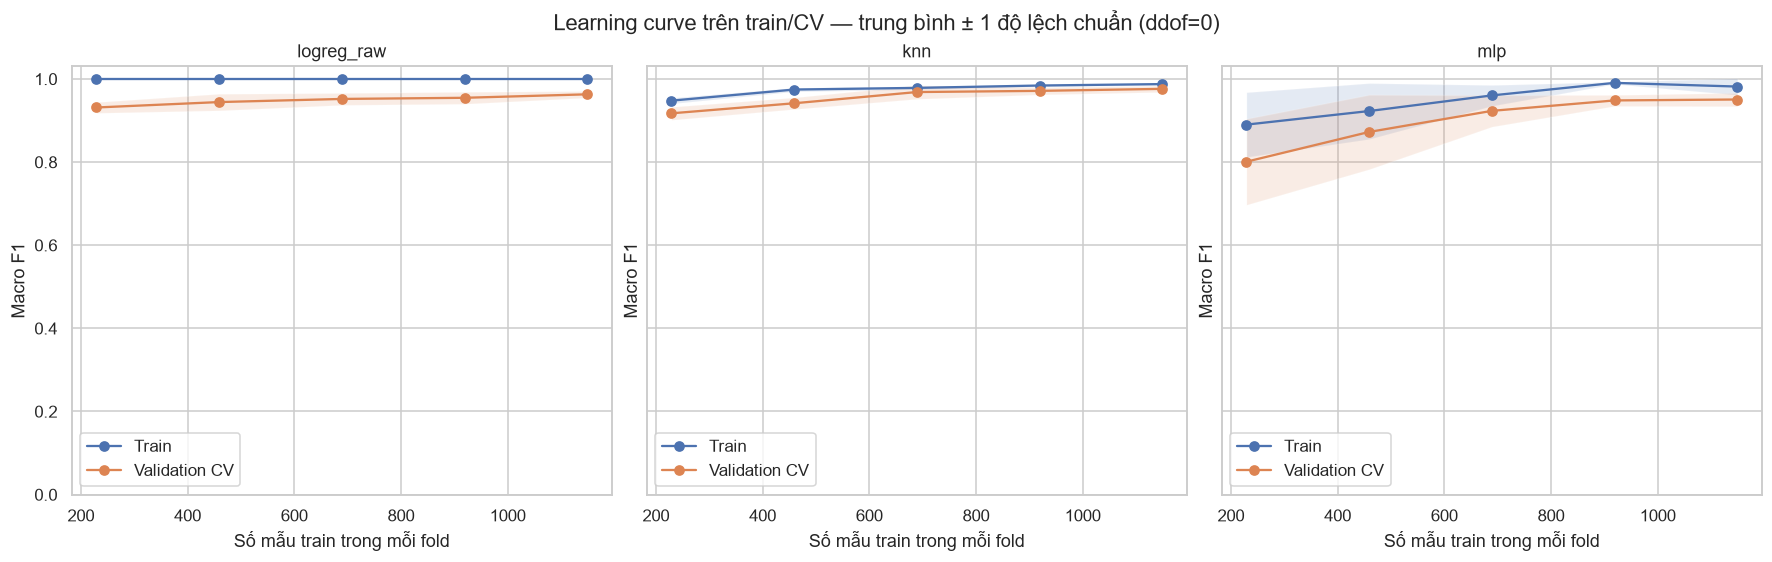

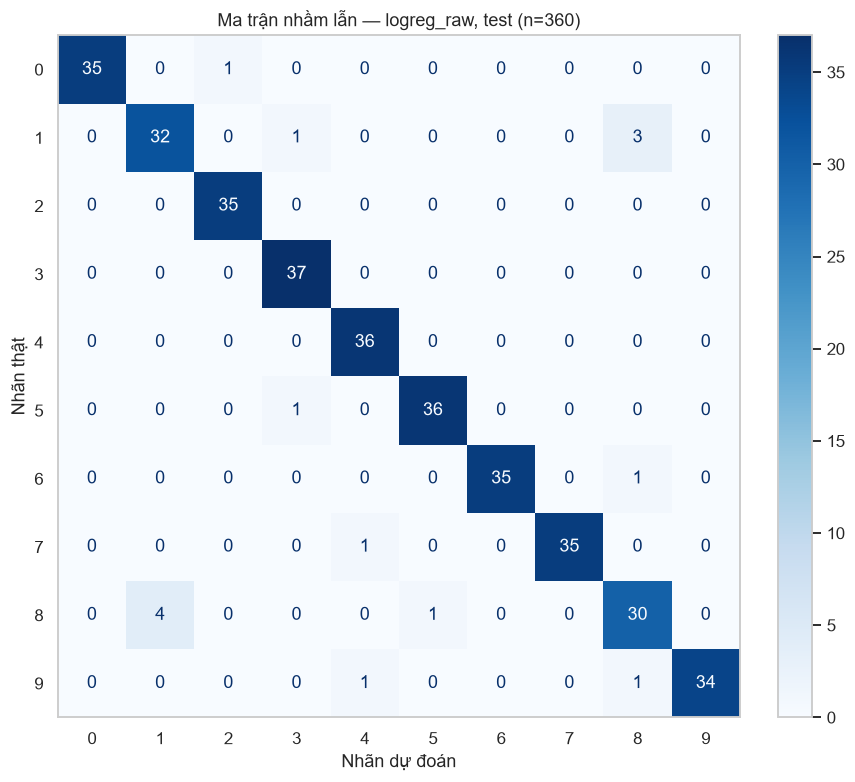

,true_label,predicted_label,count
6,8,1,4
2,1,8,3
0,0,2,1
1,1,3,1
3,5,3,1
4,6,8,1
5,7,4,1
7,8,5,1
8,9,4,1
9,9,8,1


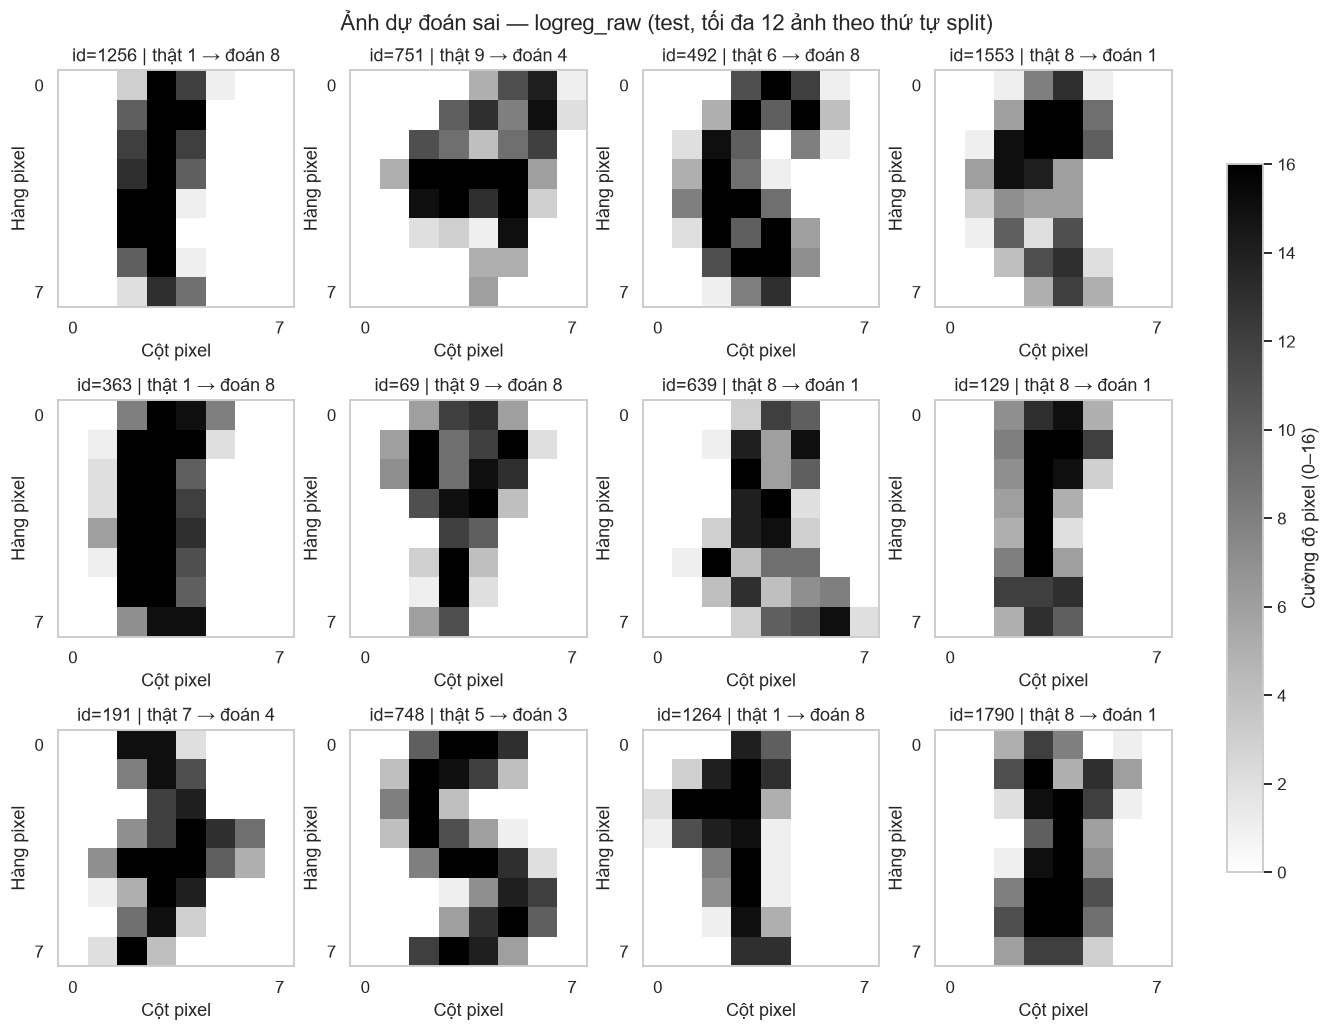

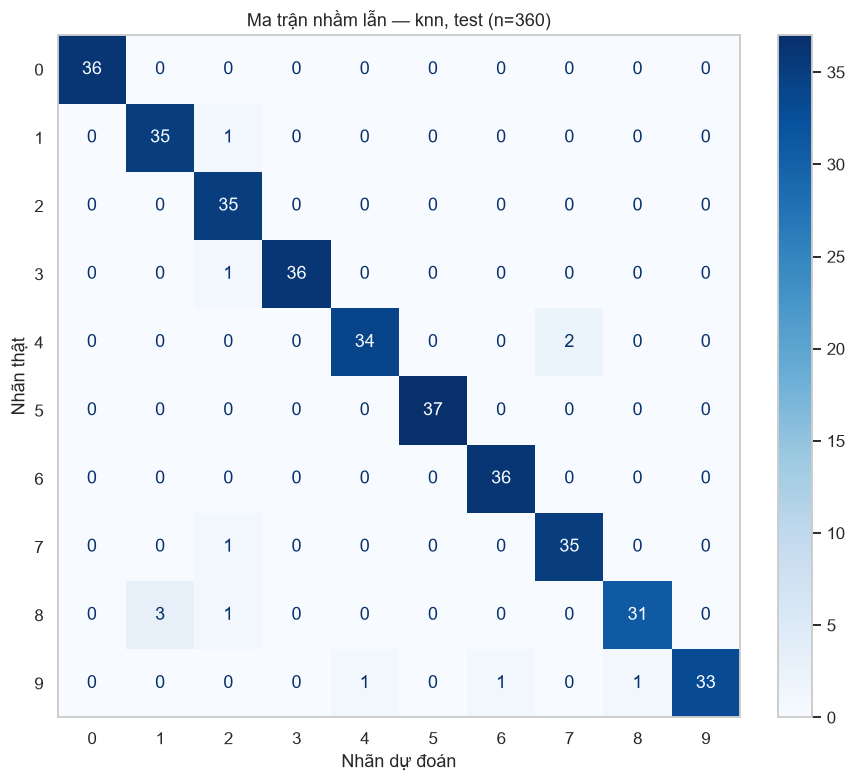

,true_label,predicted_label,count
4,8,1,3
2,4,7,2
0,1,2,1
1,3,2,1
3,7,2,1
5,8,2,1
6,9,4,1
7,9,6,1
8,9,8,1


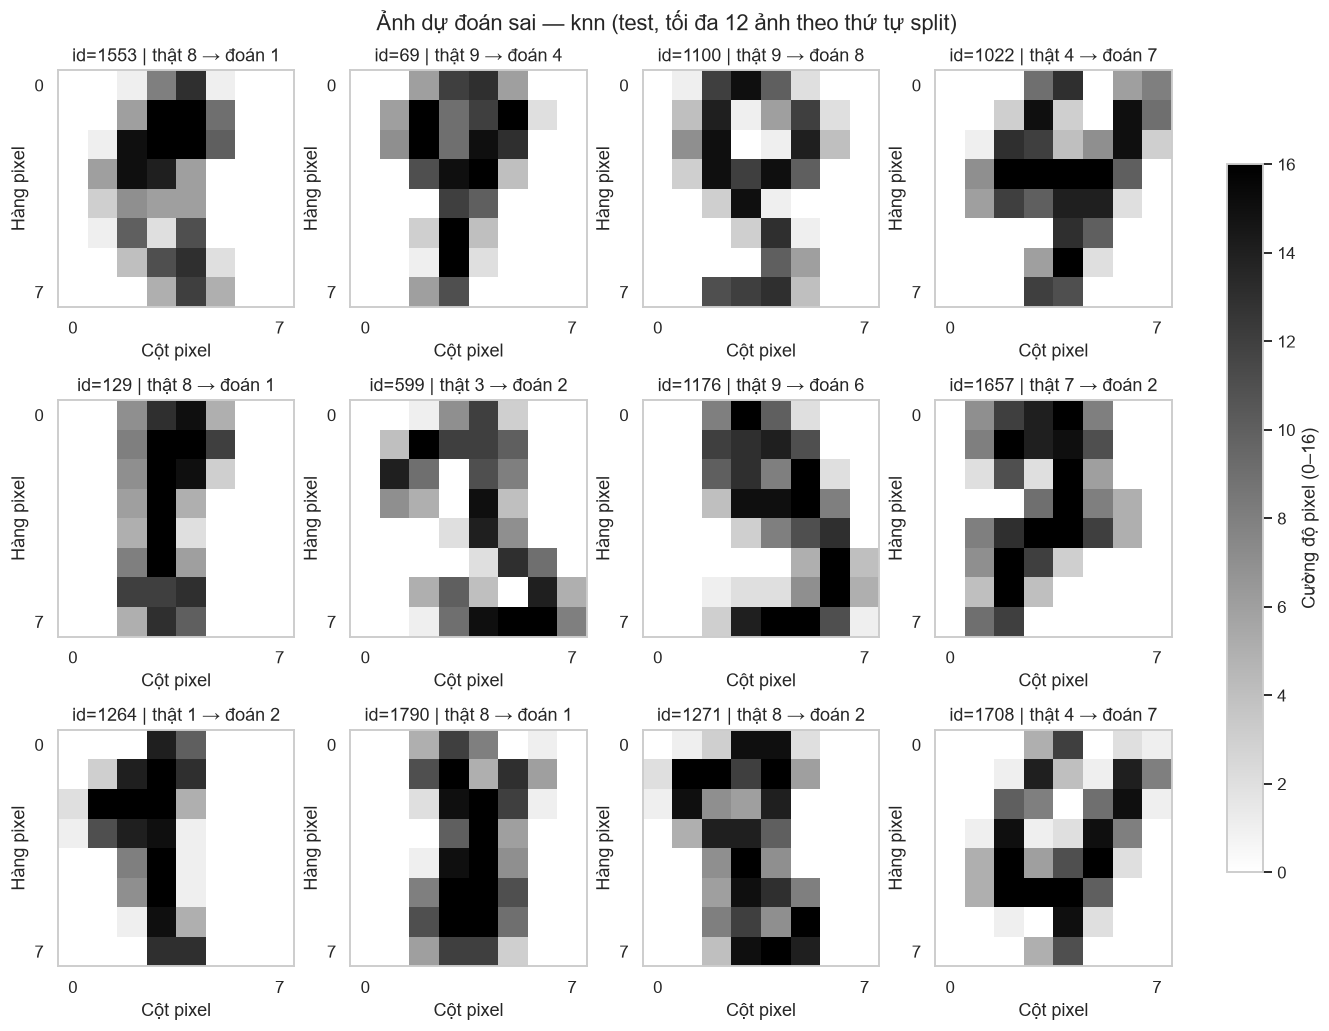

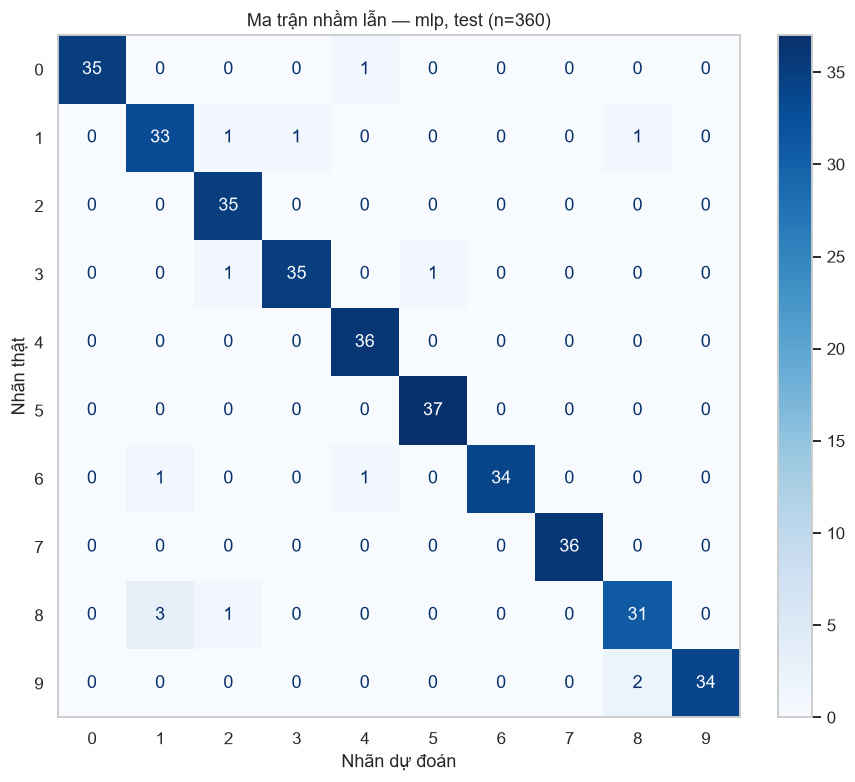

,true_label,predicted_label,count
8,8,1,3
10,9,8,2
0,0,4,1
1,1,2,1
2,1,3,1
3,1,8,1
4,3,2,1
5,3,5,1
6,6,1,1
7,6,4,1


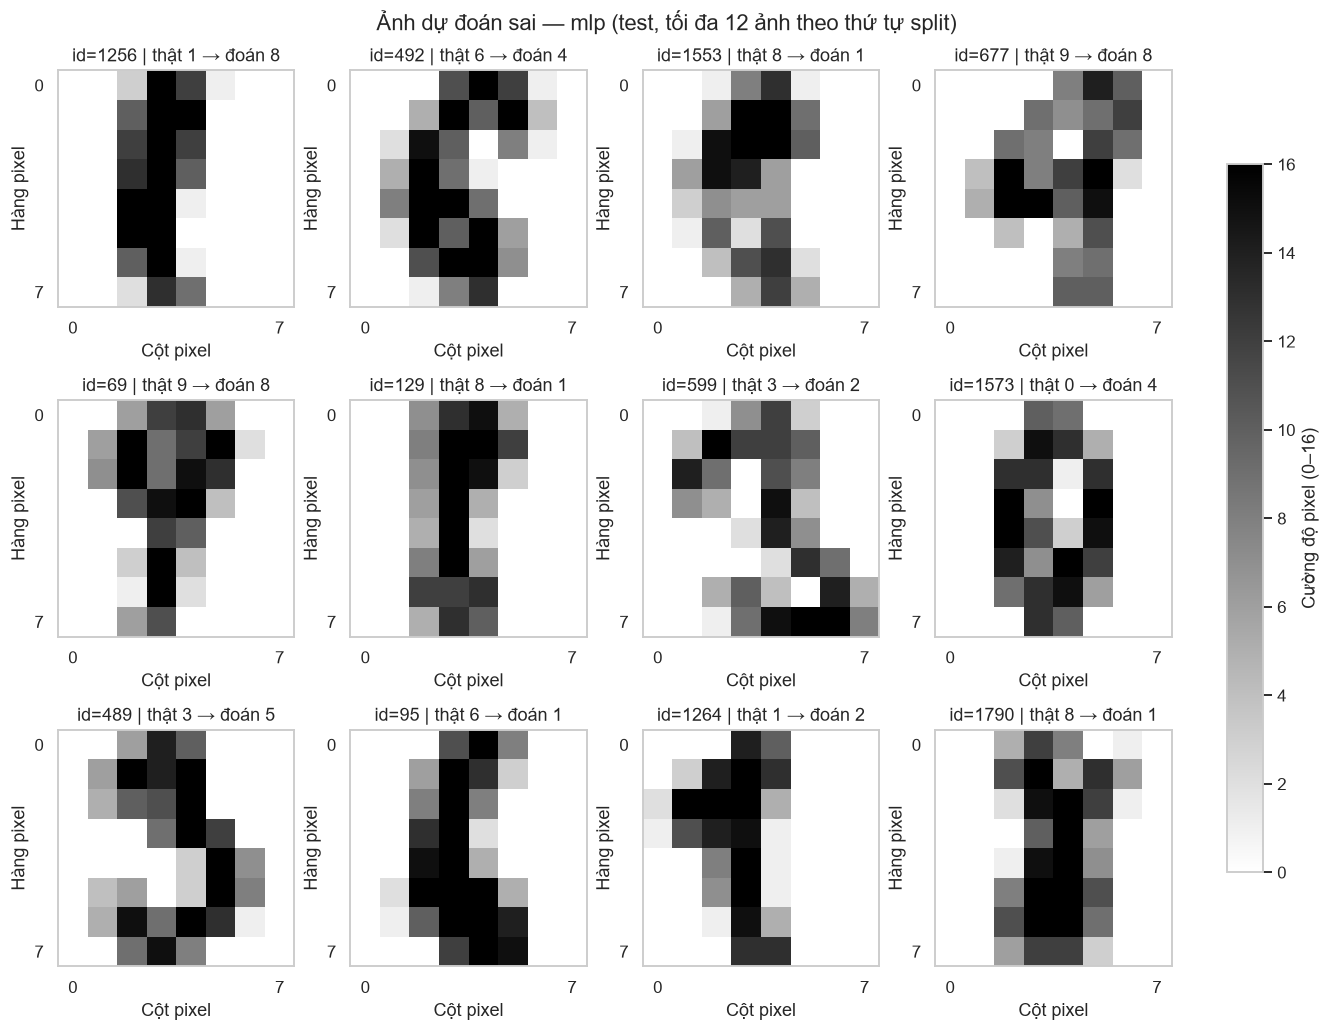

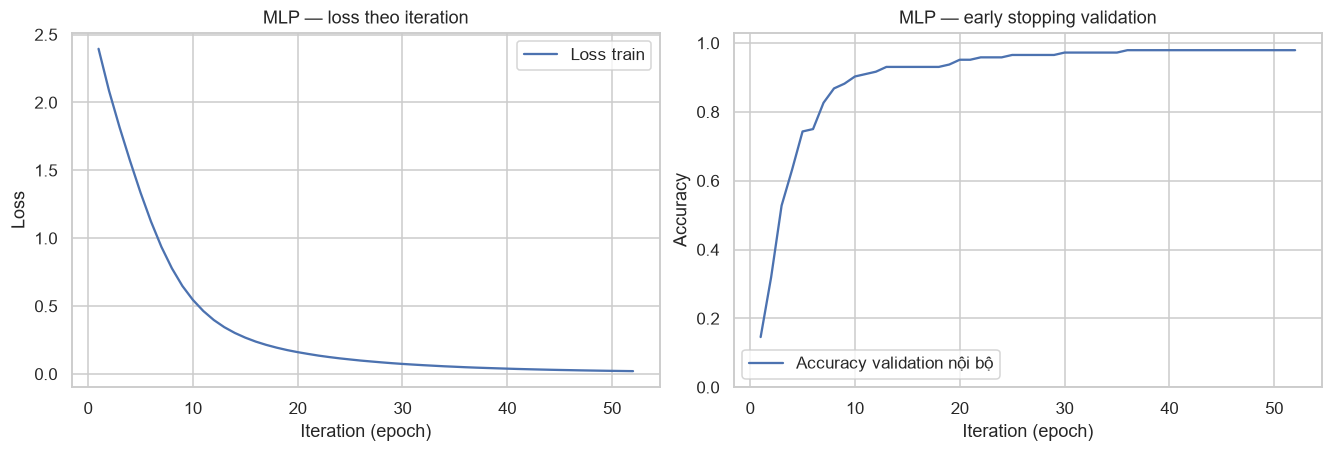

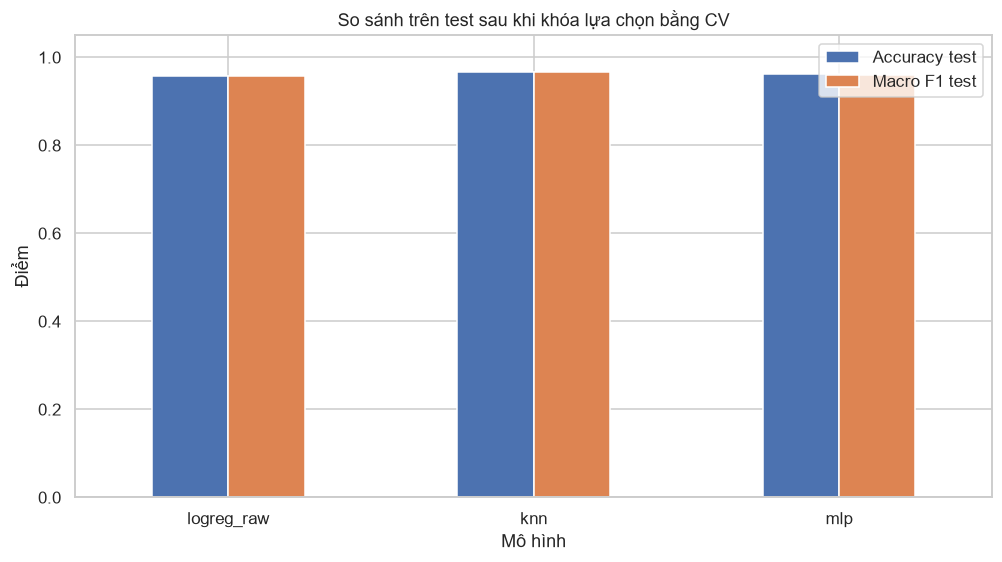

,model,accuracy,precision_macro,recall_macro,f1_macro,final_fit_time_s,predict_median_time_s,tuning_time_s,pipeline_bytes,cv_f1_macro_mean,cv_f1_macro_std
0,logreg_raw,0.958333,0.958731,0.958012,0.958075,0.098705,0.000798,0.000000,5935,0.963687,0.007866
1,knn,0.966667,0.967759,0.966424,0.966304,0.003107,0.004730,0.635378,140738,0.976170,0.007575
2,mlp,0.961111,0.961798,0.960944,0.960888,0.279319,0.001538,4.231378,159039,0.962365,0.008314


Mô hình đã chọn bằng CV, giữ nguyên sau test: knn


In [22]:
experiment_complete = False
if RUN_EXPERIMENTS:
    assert CLEANING_DECISION.strip(), "Nhóm phải ghi quyết định xử lý dữ liệu tại mục 3."
    assert STUDENT_PROTOCOL_NOTE.strip(), "Nhóm phải ghi xác nhận tiêu chí/thí nghiệm trước khi chạy."
    models = {"logreg_raw": make_baseline(), **make_comparison_models()}
    assert set(models) == {"logreg_raw", "knn", "mlp"}
    assert all(isinstance(model, Pipeline) for model in models.values())
    with threadpool_limits(limits=1):
        scaling_results = run_scaling_experiment(X_train, y_train, cv_splits)
        templates, cv_summary, cv_details, tuning_times = run_cv_searches(
            models, scaling_results, X_train, y_train, cv_splits)
    assert set(templates) == {"logreg_raw", "knn", "mlp"}
    assert set(cv_summary["model"]) == set(templates) and len(cv_summary) == 3
    assert np.isfinite(cv_summary[["cv_f1_macro_mean", "cv_f1_macro_std"]].to_numpy()).all()
    selected_name = choose_model_by_cv(cv_summary)
    expected_name = cv_summary.sort_values(["cv_f1_macro_mean", "model"], ascending=[False, True]).iloc[0]["model"]
    assert selected_name == expected_name, "Lựa chọn không đúng quy tắc CV đã đặt trước."
    selection_lock = {"selected_model": selected_name, "rule": SELECTION_RULE,
                      "cv_summary": cv_summary.to_dict(orient="records"),
                      "parameters": {name: repr(p.get_params(deep=True)) for name, p in templates.items()},
                      "cleaning_decision": CLEANING_DECISION, "student_protocol_note": STUDENT_PROTOCOL_NOTE,
                      "test_used_at_lock": False, "data_sha256": DATA_SHA256,
                      "locked_at_utc": datetime.now(timezone.utc).isoformat()}
    (OUT / "selection_lock.json").write_text(json.dumps(selection_lock, indent=2, ensure_ascii=False), encoding="utf-8")
    with threadpool_limits(limits=1):
        curve_results = draw_learning_curves(templates, X_train, y_train, cv_splits)
    final_pipelines, pipeline_blobs, reports, error_tables, timing_details = {}, {}, {}, {}, {}
    result_rows, prediction_frames = [], []
    for name, template in templates.items():
        fitted, prediction, costs, blob = measure_final_pipeline(template, X_train, y_train, X_test)
        metrics, report = evaluate_predictions(y_test, prediction)
        cm_frame, pairs, mistakes = analyze_errors(name, X_test, y_test, prediction)
        final_pipelines[name], pipeline_blobs[name], reports[name] = fitted, blob, report
        error_tables[name] = (cm_frame, pairs, mistakes)
        timing_details[name] = costs
        result_rows.append({"model": name, **metrics,
                            "final_fit_time_s": costs["final_fit_time_s"],
                            "predict_median_time_s": costs["predict_median_time_s"],
                            "tuning_time_s": tuning_times[name], "pipeline_bytes": costs["pipeline_bytes"]})
        prediction_frames.append(pd.DataFrame({"model": name, "sample_index": X_test.index,
                                                "true_label": y_test.to_numpy(), "predicted_label": prediction}))
    plot_mlp_history(final_pipelines["mlp"])
    final_results = pd.DataFrame(result_rows).merge(cv_summary, on="model", validate="one_to_one")
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    final_results.set_index("model")[["accuracy", "f1_macro"]].plot.bar(ax=ax, rot=0)
    ax.set(title="So sánh trên test sau khi khóa lựa chọn bằng CV", xlabel="Mô hình", ylabel="Điểm", ylim=(0, 1.05))
    ax.legend(["Accuracy test", "Macro F1 test"])
    save_figure(fig, "model_comparison.png")
    display(final_results)
    print("Mô hình đã chọn bằng CV, giữ nguyên sau test:", selected_name)
    experiment_complete = True
else:
    print("Đã tắt RUN_EXPERIMENTS: chỉ chạy kiểm tra dữ liệu và EDA, không fit mô hình.")


**So sánh và lựa chọn — dự thảo.**

| Mô hình | CV macro F1 mean ± std (%) | Accuracy test (%) | Macro F1 test (%) |
|---|---:|---:|---:|
| Logistic Regression thô | 96,3687 ± 0,7866 | 95,8333 | 95,8075 |
| KNN | **97,6170 ± 0,7575** | 96,6667 | 96,6304 |
| MLP | 96,2365 ± 0,8314 | 96,1111 | 96,0888 |

KNN được khóa theo CV trước test. MLP hơn baseline **0,2778 điểm phần trăm accuracy test**
và **0,2813 điểm phần trăm macro F1 test**, nhưng CV mean thấp hơn baseline khoảng 0,1322 điểm phần trăm.
Chênh lệch nhỏ trên một split không chứng minh MLP luôn tốt hơn LR. KNN hiệu quả nhất trong thực nghiệm này,
không khẳng định luôn tốt hơn MLP. Std 5 folds mô tả dao động, không phải khoảng tin cậy hay kiểm định khác biệt.

**Chuẩn hóa:** cùng MLP ban đầu và folds, mean macro F1 CV tăng từ **94,3452% lên 96,2365%**,
tăng khoảng **1,8913 điểm phần trăm** (khoảng 2,00% tương đối); std giảm từ 1,8458 xuống 0,8314 điểm phần trăm.
Đây là kết quả CV cho scaling, khác accuracy test 96,1111%. Không suy rộng rằng mọi bộ dữ liệu đều được lợi như vậy.

**Chi phí:** LR/KNN/MLP fit cuối lần lượt 0,098705/0,003107/0,279319 s; predict median trên 360 ảnh
0,000798/0,004730/0,001538 s; tuning riêng 0/0,635378/4,231378 s; Pipeline 5.935/140.738/159.039 byte.
KNN fit nhanh vì chủ yếu lưu mẫu, nhưng predict chậm nhất; LR nhỏ và predict nhanh nhất ở phép đo này.
MLP tốn tuning/fit hơn, chưa đạt điểm tốt nhất. Đây là số đo cùng máy/một luồng, fit chỉ một lần;
không coi chênh lệch thời gian nhỏ là bảo đảm trên mọi máy. Baseline không tuning vẫn tốn CV.

**Giới hạn và hướng sau:** Digits nhỏ, 8×8; split ngẫu nhiên không bảo đảm tách người viết.
CV dùng chọn tham số nên có thiên lệch lựa chọn. 10 ảnh MNIST đã thử chỉ đúng 3/10 mỗi model,
cho thấy cần thận trọng với ảnh ngoài Digits, chưa đủ ước lượng accuracy thực tế.
Tiền xử lý hợp lệ về hình học/miền pixel không bảo đảm phân phối nét trùng Digits; xác suất chưa hiệu chỉnh.
Có thể thu ảnh thật có nhãn, chốt quy trình trước và đánh giá bằng tập ngoài mới trong nghiên cứu sau;
không sửa run hiện tại theo test hoặc theo 10 ảnh đã xem. Nguồn: `model_comparison.csv`, `mlp_scaling_cv.csv`, chỉ mục kết quả.


## 16. Lưu Pipeline và xuất kết quả thực tế

Xuất toàn bộ Pipeline bằng joblib (nén mức 3); đọc lại và so sánh dự đoán test.
Mỗi run có thư mục riêng, không ghi đè kết quả cũ. models/registry.json chỉ được tạo tự động
nếu chưa có; app dùng manifest cố định này và không chọn lại bằng điểm test/mtime.
Các lần chạy notebook sau tạo run riêng nhưng không tự thay bộ mô hình đang dùng trong demo.


In [23]:
if experiment_complete:
    MODEL_OUT.mkdir(parents=True, exist_ok=False)
    final_results.to_csv(OUT / "model_comparison.csv", index=False)
    scaling_results.to_csv(OUT / "mlp_scaling_cv.csv", index=False)
    cv_summary.to_csv(OUT / "cv_summary.csv", index=False)
    curve_results.to_csv(OUT / "learning_curve.csv", index=False)
    pd.concat(prediction_frames, ignore_index=True).to_csv(OUT / "test_predictions.csv", index=False)
    for name in final_pipelines:
        cv_details[name].to_csv(OUT / f"cv_details_{name}.csv", index=False)
        report_frame = pd.DataFrame(reports[name]).T
        # accuracy là một scalar: không broadcast nó sang precision/recall/support.
        report_frame.loc["accuracy", ["precision", "recall"]] = np.nan
        report_frame.loc["accuracy", "support"] = len(y_test)
        report_frame.to_csv(OUT / f"classification_report_{name}.csv", index_label="label")
        cm_frame, pairs, mistakes = error_tables[name]
        cm_frame.to_csv(OUT / f"confusion_matrix_{name}.csv", index_label="true_label")
        pairs.to_csv(OUT / f"confusion_pairs_{name}.csv", index=False)
        mistakes.to_csv(OUT / f"misclassified_{name}.csv", index=False)
        (OUT / f"classification_report_{name}.json").write_text(json.dumps(reports[name], indent=2), encoding="utf-8")
        model_path = MODEL_OUT / f"{name}.joblib"
        # Blob này chính là kết quả joblib.dump(Pipeline, compress=3) ở mục 12.
        model_path.write_bytes(pipeline_blobs[name])
        restored = joblib.load(model_path)
        assert np.array_equal(restored.predict(X_test), final_pipelines[name].predict(X_test))
        assert model_path.stat().st_size == timing_details[name]["pipeline_bytes"]
    (OUT / "timing_details.json").write_text(json.dumps(timing_details, indent=2), encoding="utf-8")
    mlp_clf = final_pipelines["mlp"].named_steps["clf"]
    history = {"loss_curve": getattr(mlp_clf, "loss_curve_", None),
               "validation_scores": getattr(mlp_clf, "validation_scores_", None),
               "n_iter": int(mlp_clf.n_iter_), "best_validation_score": getattr(mlp_clf, "best_validation_score_", None)}
    (OUT / "mlp_history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
    (MODEL_OUT / "metadata.json").write_text(json.dumps({"selected_model": selected_name,
        "run_id": RUN_ID, "environment": environment, "data_sha256": DATA_SHA256,
        "input_shape": [None, 64], "pixel_range": [0, 16], "labels": LABELS.tolist(),
        "selection_lock": f"outputs/{RUN_ID}/selection_lock.json"}, indent=2, ensure_ascii=False), encoding="utf-8")
    registry = {"run_id": RUN_ID, "selected_model": selected_name,
                "sklearn_version": version("scikit-learn"),
                "models": {name: {"path": f"{RUN_ID}/{name}.joblib",
                           "sha256": hashlib.sha256(pipeline_blobs[name]).hexdigest()}
                           for name in final_pipelines}}
    registry_path = ROOT / "models" / "registry.json"
    if not registry_path.exists():
        registry_path.write_text(json.dumps(registry, indent=2), encoding="utf-8")
    else:
        print("Giữ nguyên registry demo hiện có; run mới không tự thay mô hình đang dùng.")
    print("Đã xuất kết quả thật:", OUT.relative_to(ROOT).as_posix(), "và", MODEL_OUT.relative_to(ROOT).as_posix())
status = {"support_run_completed": True, "experiments_completed": experiment_complete,
          "selected_model": selected_name if experiment_complete else None,
          "pending_student_tasks": ["Nhận định EDA, phân tích kết quả, báo cáo/slide và phân công thực tế"],
          "student_interpretations_reviewed": False, "ready_to_submit": False,
          "note": "Kết quả đo trực tiếp; nhóm cần tự viết phân tích và rà soát trước nộp."}
(OUT / "run_status.json").write_text(json.dumps(status, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.Series(status))


Đã xuất kết quả thật: outputs\20261117T081201Z_fd32180f và models\20261117T081201Z_fd32180f


support_run_completed                                                            True
experiments_completed                                                            True
selected_model                                                                    knn
pending_student_tasks               [Nhận định EDA, phân tích kết quả, báo cáo/sli...
student_interpretations_reviewed                                                False
ready_to_submit                                                                 False
note                                Kết quả đo trực tiếp; nhóm cần tự viết phân tí...
dtype: object

### Trả lời 5 câu hỏi đề tài 13 — dự thảo để nhóm xác nhận

1. **Biểu diễn và chuẩn hóa:** 1.797 ảnh 8×8 thành X=(1797,64), y=(1797,), pixel 0–16.
   Flatten theo hàng; scaler chỉ học train trong fold. MLP có scaling đạt CV macro F1 96,2365%, thô 94,3452% (mục 2, 5, 7–8, 15).
2. **Baseline và MLP:** LR thô accuracy test 95,8333%, MLP 96,1111%; tăng 0,2778 điểm phần trăm,
   nhưng CV MLP không vượt LR. Không diễn giải thành cải thiện chắc chắn (mục 6, 9, 15).
3. **Nhầm lẫn:** 8→1 nhiều nhất ở cả ba model; LR 4 lần, KNN/MLP 3 lần.
   KNN còn 4→7 hai lần; đối chiếu ảnh 1553 và 1022 (mục 13, 15).
4. **Learning curve/overfitting:** train cao hơn validation ở mốc cuối, gap 3,70/1,15/3,11 điểm phần trăm;
   validation tăng theo số mẫu. MLP loss giảm, validation nội bộ bão hòa; không xác định chính xác epoch quá khớp (mục 14–15).
5. **Chi phí/độ chính xác:** KNN thắng CV và test ở run này, fit nhanh nhưng predict chậm nhất;
   LR nhẹ nhất, MLP tuning tốn nhất. So sánh cùng train/test, một luồng, tuning đo riêng (mục 12, 15).

Nhóm cần kiểm tra các dự thảo, xác nhận hoặc sửa cách diễn đạt, bổ sung thông tin cá nhân/phân công thật,
hoàn thiện báo cáo 10 mục và slide, tập giải thích/thay đổi chương trình. `run_status.json` là snapshot
tại thời điểm huấn luyện, không phải trạng thái xác nhận mới. Xem HANDOFF.md để biết kiểm thử và công việc còn lại.
